In [3]:
import numpy as np
import matplotlib.pyplot as plt

# *Network Setup*

## **Activation**

In [4]:
def relu(Z):
    A=np.maximum(0,Z)
    assert(A.shape==Z.shape)
    cache=Z
    
    return A, cache

def sigmoid(Z):
    A=1/(1+np.exp(-Z))
    cache=Z
    
    return A,cache

## **Back Propagation**

In [5]:
def relu_backward(dA,cache):
    Z=cache
    dZ=np.array(dA,copy=True)
    dZ[Z<=0]=0
    assert(dZ.shape==Z.shape)
    return dZ

def sigmoid_backward(dA,cache):
    Z=cache
    a=1/(1+np.exp(-Z))
    dZ=dA * s * (1-s)
    assert(dZ.shape==Z.shape)
    return dZ

## **Network**

In [6]:
np.random.seed(1)

In [7]:
def initialize_parameters(n_x,n_h,n_y):
    np.random.seed(1)
    W1=np.random.randn(n_x,n_h)*0.01
    b1=np.zeros((n_h,1))
    W2=np.random.randn(n_y,n_h)*0.01
    b2=np.zeros((n_y,1))
    
    assert(W1.shape == (n_h, n_x))
    assert(b1.shape == (n_h, 1))
    assert(W2.shape == (n_y, n_h))
    assert(b2.shape == (n_y, 1))
    
    parameters={
        'W1':W1,
        'b1':b1,
        'W2':W2,
        'b2':b2
    }
    return parameters

initialize Deep parameters

In [8]:

def initialiize_parameters_deep(layer_dims):
    np.random.seed(3)
    parameters={}
    L=len(layer_dims)
    
    for l in range(1,L):
        parameters['W'+str(l)]=np.random.randn(layer_dims[l],layer_dims[l-1])#*0.01
        parameters['b'+str(l)]=np.zeros((layer_dims[l],1))
        
        assert(parameters['W'+str(l)].shape==(layer_dims[l],layer_dims[l-1]))
        assert(parameters['b'+str(l)].shape==((layer_dims[l],1)))
    return parameters

## **Forward propagation module**

In [9]:
def linear_forward(A,W,b):
    Z=np.dot(W,A)+b
    cache=[W,A,b]
    return Z, cache

In [10]:
def linear_activation_forward(A_prev,W,b,activation):
    if activation=='sigmoid':
        Z,linear_cache=linear_forward(A_prev,W,b)
        A,activation_cache=sigmoid(Z)
        
    if activation=='relu':
        Z,linear_cache=linear_forward(A_prev,W,b)
        A,activation_cache=relu(Z)
    
    cache=(linear_cache,activation_cache)
    return A, cache

## **L Model Forward**

In [11]:
def L_model_forward(X,parameters):
    caches=[]
    A=X
    L=len(parameters)//2
    for l in range (1,L):
        A_prev=A
        A,cache=linear_activation_forward(A_prev,parameters['W'+str(l)],parameters['b'+str(l)],activation="relu")
        caches.append(cache)
    AL,cache=linear_activation_forward(A,parameters[A,parameters['W'+str(L)],parameters['b'+str(L)]],activation="sigmoid")
    caches.append(cache)
    return AL,caches

## **Cost Function**

In [12]:
def compute_cost(AL,Y):
    m=Y.shape[1]
    cost=-(1/m)*np.sum(np.multiply(np.log(AL),Y)+(np.multiply(np.log(1-AL),1-Y)))
    cost=np.squeeze(cost)
    return cost

## **Backward Propagation**

In [13]:

def linear_backward(dZ,cache):
    A_prev,W,b=cache
    m=A_prev.shape[1]
    dW=-(1/m)*np.dot(dZ,A_prev.T)
    db=-(1/m)*np.sum(dZ,axis=1,keepdims=True)
    dA_prev=np.dot(W.T,dZ)
    assert (dA_prev.shape == A_prev.shape)
    assert (dW.shape == W.shape)
    assert (db.shape == b.shape)
    return dA_prev,dW,db

linear activation backward

In [14]:
def linear_activation_backward(dA,cache,activation):
    linear_cache,activation_cache=cache
    if activation=="relu":
        dZ=relu_backward(dA,activation_cache)
        dA_prev,dW,db=linear_backward(dZ,linear_cache)
    if activation=="sigmoid":
        dZ=sigmoid_backward(dA,activation_cache)
        dA_prev,dW,db=linear_backward(dZ,linear_cache)
    return dA_prev,dW,db

L model Backward

In [15]:
def L_model_backward(AL,Y,caches):
    grads={}
    L=len(caches)
    m=AL.shape[1]
    Y=Y.reshape(AL.shape)
    dAL=-(np.divide(Y,AL)-np.divide(1-Y,1-AL))
    current_cache=caches[L-1]
    dA_prev_temp,dW_temp.db_temp=linear_activation_backward(dAL,current_cache,activation="sigmoid")
    grads["dA"+str(L-1)]=dA_prev_temp
    grads["dW"+str(L)]=dW_temp
    grads["db"+str(L)]=db_temp
    for l in reversed(range(L-1)):
        current_cache=caches[l]
        dA_prev_temp,dW_temp,db_temp=linear_activation_backward(grads["dA"+str(l+1)],current_cache,activation="relu")
        grads["dA"+str(L-1)]=dA_prev_temp
        grads["dW"+str(L)]=dW_temp
        grads["db"+str(L)]=db_temp
    return grads

## **Update Parameters**

In [16]:
import copy

In [17]:
def update_parameters(params,grads,learning_rate):
    parameters=copy.deepcopy(params)
    L=len(parameters)//2
    for l in range(L):
        parameters["W"+str(l+1)]=parameters["W"+str(l+1)]-learning_rate*grads["dW"+str(l+1)]
        parameters["b"+str(l+1)]=parameters["b"+str(l+1)]-learning_rate*grads["db"+str(l+1)]
    return parameters

## **predict**

In [18]:
def predict(X,y,parameters):
    m=X.shape[1]
    n=len(parameters)
    p=np.zeros((1,m))
    probas,caches=L_model_forward(X,parameters)
    for i in range(0,probas.shape[1]):
        if probas[0,i]>0.5:
            p[0,i]=1
        else:
            p[0,i]=0
    print("Accuracy:"+str(np.sum(p==y)/m))
    return p

In [19]:
def print_mislable_images(classes,X,y,p):
    a=p+y
    mislable_indices=np.asanyarray(np.where(a==1))
    plt.rcParams["figure.figsize"]=(40.0,40.0)
    num_images=len(mislable_images[0])
    for i in range(num_images):
        index=mislable_images[1][i]
        plt.subplot(2,num_images,i+1)
        plt.imshow(X[:,index].reshape(64,64,3),interpolation='nearest')
        plt.axis('off')
        plt.title("prediction:"+classes[int(p[0,index])].decode("utf-8")+"\nClass:"+classes[y[0,index]].decode("utf-8"))

# **Dogs not dogs**

## **Dataset**

In [26]:

import h5py
import numpy as np
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split

# Dataset location: folder containing dog/ and other/
ROOT = Path("/Users/rayquaza/Desktop/Resources/Deep Learning/Neural Network and Deep Learning/Deep Neural Networks/W4A1/dog_classifier/Dog vs Not-Dog")

OUTPUT = "dog_dataset.h5"
SIZE = (128, 128)

# 1 = Dog, 0 = Other
classes = {"dog": 1, "other": 0}

# Collect valid images
files, labels = [], []

for folder, label in classes.items():
    for path in (ROOT / folder).rglob("*"):
        if path.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
            try:
                with Image.open(path) as img:
                    img.verify()

                files.append(path)
                labels.append(label)

            except Exception:
                print("Skipping corrupted:", path)

labels = np.array(labels)

print("Total images:", len(files))
print("Dog images:", np.sum(labels == 1))
print("Other images:", np.sum(labels == 0))

# Split 80% train, 20% test
train_files, test_files, y_train, y_test = train_test_split(
    files,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

# Write images and labels to HDF5
def save_group(h5, name, paths, targets):

    group = h5.create_group(name)

    images = group.create_dataset(
        "images",
        shape=(len(paths), 128, 128, 3),
        dtype="uint8",
        compression="lzf",
        chunks=(32, 128, 128, 3)
    )

    group.create_dataset(
        "labels",
        data=targets,
        dtype="int64"
    )

    read_time = 0
    write_time = 0
    start = time.time()

    for i, path in enumerate(paths):

        t1 = time.time()

        with Image.open(path) as img:
            img = img.convert("RGB").resize(SIZE)
            arr = np.asarray(img, dtype=np.uint8)

        t2 = time.time()

        images[i] = arr

        t3 = time.time()

        read_time += t2 - t1
        write_time += t3 - t2

        if (i + 1) % 100 == 0:
            elapsed = time.time() - start

            print(
                f"{name}: {i+1}/{len(paths)} | "
                f"Read: {read_time:.2f}s | "
                f"Write: {write_time:.2f}s | "
                f"Total: {elapsed:.2f}s"
            )

with h5py.File(OUTPUT, "w") as h5:

    save_group(h5, "train", train_files, y_train)
    save_group(h5, "test", test_files, y_test)

print("\nConversion completed!")
print("HDF5 file:", OUTPUT)


KeyboardInterrupt: 

In [4]:
import time
import h5py
import numpy as np
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split

# Dataset location: folder containing dog/ and other/
ROOT = Path("/Users/rayquaza/Desktop/Resources/Deep Learning/Neural Network and Deep Learning/Deep Neural Networks/W4A1/dog_classifier/Dog vs Not-Dog")

OUTPUT = "dog_dataset2.h5"
SIZE = (64, 64)

# 1 = Dog, 0 = Other
classes = {"dog": 1, "other": 0}

# Collect valid images
files, labels = [], []

for folder, label in classes.items():
    for path in (ROOT / folder).rglob("*"):
        if path.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]:
            try:
                with Image.open(path) as img:
                    img.verify()

                files.append(path)
                labels.append(label)

            except Exception:
                print("Skipping corrupted:", path)

labels = np.array(labels)

print("Total images:", len(files))
print("Dog images:", np.sum(labels == 1))
print("Other images:", np.sum(labels == 0))

# Split 80% train, 20% test
train_files, test_files, y_train, y_test = train_test_split(
    files,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

# Write images and labels to HDF5
def save_group(h5, name, paths, targets):

    group = h5.create_group(name)

    images = group.create_dataset(
        "images",
        shape=(len(paths), 64, 64, 3),
        dtype="uint8",
        compression="lzf",
        chunks=(32, 64, 64, 3)
    )

    group.create_dataset(
        "labels",
        data=targets,
        dtype="int64"
    )

    read_time = 0
    write_time = 0
    start = time.time()

    for i, path in enumerate(paths):

        t1 = time.time()

        with Image.open(path) as img:
            img = img.convert("RGB").resize(SIZE)
            arr = np.asarray(img, dtype=np.uint8)

        t2 = time.time()

        images[i] = arr

        t3 = time.time()

        read_time += t2 - t1
        write_time += t3 - t2

        if (i + 1) % 100 == 0:
            elapsed = time.time() - start

            print(
                f"{name}: {i+1}/{len(paths)} | "
                f"Read: {read_time:.2f}s | "
                f"Write: {write_time:.2f}s | "
                f"Total: {elapsed:.2f}s"
            )

with h5py.File(OUTPUT, "w") as h5:

    save_group(h5, "train", train_files, y_train)
    save_group(h5, "test", test_files, y_test)

print("\nConversion completed!")
print("HDF5 file:", OUTPUT)


Total images: 25124
Dog images: 12562
Other images: 12562
train: 100/20099 | Read: 0.68s | Write: 0.01s | Total: 0.70s
train: 200/20099 | Read: 1.26s | Write: 0.02s | Total: 1.28s
train: 300/20099 | Read: 1.85s | Write: 0.03s | Total: 1.89s
train: 400/20099 | Read: 2.68s | Write: 0.04s | Total: 2.72s
train: 500/20099 | Read: 3.25s | Write: 0.05s | Total: 3.31s
train: 600/20099 | Read: 3.70s | Write: 0.06s | Total: 3.76s
train: 700/20099 | Read: 4.62s | Write: 0.07s | Total: 4.69s
train: 800/20099 | Read: 5.19s | Write: 0.08s | Total: 5.28s
train: 900/20099 | Read: 6.18s | Write: 0.09s | Total: 6.27s
train: 1000/20099 | Read: 7.23s | Write: 0.10s | Total: 7.34s
train: 1100/20099 | Read: 7.91s | Write: 0.12s | Total: 8.02s
train: 1200/20099 | Read: 8.62s | Write: 0.12s | Total: 8.75s
train: 1300/20099 | Read: 9.26s | Write: 0.13s | Total: 9.40s
train: 1400/20099 | Read: 10.04s | Write: 0.14s | Total: 10.18s
train: 1500/20099 | Read: 10.61s | Write: 0.15s | Total: 10.77s
train: 1600/20099

In [1]:
import h5py

with h5py.File("dog_dataset2.h5", "r") as f:
    def show(name, obj):
        print(name, obj.shape if isinstance(obj, h5py.Dataset) else "")

    f.visititems(show)

test 
test/images (5025, 64, 64, 3)
test/labels (5025,)
train 
train/images (20099, 64, 64, 3)
train/labels (20099,)


In [12]:
import h5py
import numpy as np

with h5py.File("dog_dataset2.h5", "r") as f:
    train_x_orig = f["train/images"][:]
    train_y = f["train/labels"][:]

    test_x_orig = f["test/images"][:]
    test_y = f["test/labels"][:]

In [13]:
# Reshape the training and test examples 
train_x_flatten = train_x_orig.reshape(train_x_orig.shape[0], -1).T   # The "-1" makes reshape flatten the remaining dimensions
test_x_flatten = test_x_orig.reshape(test_x_orig.shape[0], -1).T

# Standardize data to have feature values between 0 and 1.
train_x = train_x_flatten/255.
test_x = test_x_flatten/255.

print ("train_x's shape: " + str(train_x.shape))
print ("test_x's shape: " + str(test_x.shape))

train_x's shape: (12288, 20099)
test_x's shape: (12288, 5025)


In [14]:
train_y=train_y.reshape(1,train_y.shape[0])
test_y=test_y.reshape(1,test_y.shape[0])

In [7]:
train_y.shape[1]

20099

## **Code**

In [15]:
def sigmoid(Z):
    A = 1/(1+np.exp(-Z))
    cache = Z
    
    return A, cache

def relu(Z):
    A = np.maximum(0,Z)
    
    assert(A.shape == Z.shape)
    
    cache = Z 
    return A, cache


def relu_backward(dA, cache):
    Z = cache
    dZ = np.array(dA, copy=True) # just converting dz to a correct object.
    
    # When z <= 0, you should set dz to 0 as well. 
    dZ[Z <= 0] = 0
    
    assert (dZ.shape == Z.shape)
    
    return dZ

def sigmoid_backward(dA, cache):
    Z = cache
    
    s = 1/(1+np.exp(-Z))
    dZ = dA * s * (1-s)
    
    assert (dZ.shape == Z.shape)
    
    return dZ


def initialize_parameters(n_x, n_h, n_y):
    np.random.seed(1)
    
    W1 = np.random.randn(n_h, n_x)*0.01
    b1 = np.zeros((n_h, 1))
    W2 = np.random.randn(n_y, n_h)*0.01
    b2 = np.zeros((n_y, 1))
    
    assert(W1.shape == (n_h, n_x))
    assert(b1.shape == (n_h, 1))
    assert(W2.shape == (n_y, n_h))
    assert(b2.shape == (n_y, 1))
    
    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2}
    
    return parameters     


def initialize_parameters_deep(layer_dims):
    np.random.seed(1)
    parameters = {}
    L = len(layer_dims)            # number of layers in the network

    for l in range(1, L):
        parameters['W' + str(l)] = np.random.randn(layer_dims[l], layer_dims[l-1]) / np.sqrt(layer_dims[l-1]) #*0.01
        parameters['b' + str(l)] = np.zeros((layer_dims[l], 1))
        
        assert(parameters['W' + str(l)].shape == (layer_dims[l], layer_dims[l-1]))
        assert(parameters['b' + str(l)].shape == (layer_dims[l], 1))

        
    return parameters

def linear_forward(A, W, b):
    Z = W.dot(A) + b
    
    assert(Z.shape == (W.shape[0], A.shape[1]))
    cache = (A, W, b)
    
    return Z, cache

def linear_activation_forward(A_prev, W, b, activation):
    if activation == "sigmoid":
        # Inputs: "A_prev, W, b". Outputs: "A, activation_cache".
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = sigmoid(Z)
    
    elif activation == "relu":
        # Inputs: "A_prev, W, b". Outputs: "A, activation_cache".
        Z, linear_cache = linear_forward(A_prev, W, b)
        A, activation_cache = relu(Z)
        
    else:
        print("\033[91mError! Please make sure you have passed the value correctly in the \"activation\" parameter")
    
    assert (A.shape == (W.shape[0], A_prev.shape[1]))
    cache = (linear_cache, activation_cache)

    return A, cache

def L_model_forward(X, parameters):
    caches = []
    A = X
    L = len(parameters) // 2                  # number of layers in the neural network
    
    # Implement [LINEAR -> RELU]*(L-1). Add "cache" to the "caches" list.
    for l in range(1, L):
        A_prev = A 
        A, cache = linear_activation_forward(A_prev, parameters['W' + str(l)], parameters['b' + str(l)], activation = "relu")
        caches.append(cache)
    
    # Implement LINEAR -> SIGMOID. Add "cache" to the "caches" list.
    AL, cache = linear_activation_forward(A, parameters['W' + str(L)], parameters['b' + str(L)], activation = "sigmoid")
    caches.append(cache)
    
    assert(AL.shape == (1,X.shape[1]))
            
    return AL, caches

def compute_cost(AL, Y):
    m = Y.shape[1]

    # Compute loss from aL and y.
    cost = (1./m) * (-np.dot(Y,np.log(AL).T) - np.dot(1-Y, np.log(1-AL).T))
    
    cost = np.squeeze(cost)      # To make sure your cost's shape is what we expect (e.g. this turns [[17]] into 17).
    assert(cost.shape == ())
    
    return cost

def linear_backward(dZ, cache):
    A_prev, W, b = cache
    m = A_prev.shape[1]

    dW = 1./m * np.dot(dZ,A_prev.T)
    db = 1./m * np.sum(dZ, axis = 1, keepdims = True)
    dA_prev = np.dot(W.T,dZ)
    
    assert (dA_prev.shape == A_prev.shape)
    assert (dW.shape == W.shape)
    assert (db.shape == b.shape)
    
    return dA_prev, dW, db

def linear_activation_backward(dA, cache, activation):
    linear_cache, activation_cache = cache
    
    if activation == "relu":
        dZ = relu_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)
        
    elif activation == "sigmoid":
        dZ = sigmoid_backward(dA, activation_cache)
        dA_prev, dW, db = linear_backward(dZ, linear_cache)
        
    else:
        print("\033[91mError! Please make sure you have passed the value correctly in the \"activation\" parameter")
    
    return dA_prev, dW, db

def L_model_backward(AL, Y, caches):
    grads = {}
    L = len(caches) # the number of layers
    m = AL.shape[1]
    Y = Y.reshape(AL.shape) # after this line, Y is the same shape as AL
    
    # Initializing the backpropagation
    dAL = - (np.divide(Y, AL) - np.divide(1 - Y, 1 - AL))
    
    # Lth layer (SIGMOID -> LINEAR) gradients. Inputs: "AL, Y, caches". Outputs: "grads["dAL"], grads["dWL"], grads["dbL"]
    current_cache = caches[L-1]
    grads["dA" + str(L-1)], grads["dW" + str(L)], grads["db" + str(L)] = linear_activation_backward(dAL, current_cache, activation = "sigmoid")
    
    for l in reversed(range(L-1)):
        # lth layer: (RELU -> LINEAR) gradients.
        current_cache = caches[l]
        dA_prev_temp, dW_temp, db_temp = linear_activation_backward(grads["dA" + str(l + 1)], current_cache, activation = "relu")
        grads["dA" + str(l)] = dA_prev_temp
        grads["dW" + str(l + 1)] = dW_temp
        grads["db" + str(l + 1)] = db_temp

    return grads

def update_parameters(parameters, grads, learning_rate):
    L = len(parameters) // 2 # number of layers in the neural network

    # Update rule for each parameter. Use a for loop.
    for l in range(L):
        parameters["W" + str(l+1)] = parameters["W" + str(l+1)] - learning_rate * grads["dW" + str(l+1)]
        parameters["b" + str(l+1)] = parameters["b" + str(l+1)] - learning_rate * grads["db" + str(l+1)]
        
    return parameters

def predict(X, y, parameters):
    m = X.shape[1]
    n = len(parameters) // 2 # number of layers in the neural network
    p = np.zeros((1,m))
    
    # Forward propagation
    probas, caches = L_model_forward(X, parameters)

    
    # convert probas to 0/1 predictions
    for i in range(0, probas.shape[1]):
        if probas[0,i] > 0.5:
            p[0,i] = 1
        else:
            p[0,i] = 0
    
    #print results
    #print ("predictions: " + str(p))
    #print ("true labels: " + str(y))
    print("Accuracy: "  + str(np.sum((p == y)/m)))
        
    return p

def print_mislabeled_images(classes, X, y, p):
    a = p + y
    mislabeled_indices = np.asarray(np.where(a == 1))
    plt.rcParams['figure.figsize'] = (40.0, 40.0) # set default size of plots
    num_images = len(mislabeled_indices[0])
    for i in range(num_images):
        index = mislabeled_indices[1][i]
        
        plt.subplot(2, num_images, i + 1)
        plt.imshow(X[:,index].reshape(64,64,3), interpolation='nearest')
        plt.axis('off')
        plt.title("Prediction: " + classes[int(p[0,index])].decode("utf-8") + " \n Class: " + classes[y[0,index]].decode("utf-8"))


In [26]:
train_x_small = train_x[:, :2009]
train_y_small = train_y[:, :2009]

In [27]:
def L_layer_model(X, Y, layers_dims, learning_rate = 0.0075, num_iterations = 3000, print_cost=False):
    np.random.seed(1)
    costs = []                         # keep track of cost
    parameters=initialize_parameters_deep(layers_dims)
    for i in range(0, num_iterations):
        AL,caches=L_model_forward(X,parameters)
        cost=compute_cost(AL,Y)
        grads=L_model_backward(AL,Y,caches)
        parameters=update_parameters(parameters,grads,learning_rate)
        if print_cost and (i % 100 == 0 or i == num_iterations - 1):
            print("Cost after iteration {}: {}".format(i, np.squeeze(cost)))
        if i % 100 == 0:
            costs.append(cost)
    
    return parameters, costs

In [28]:
layers_dims=[12288,7,1]

In [29]:
parameters, costs = L_layer_model(train_x_small, train_y_small, layers_dims, num_iterations = 1000, print_cost = True)


Cost after iteration 0: 0.6881182913936212
Cost after iteration 100: 0.6350757682087267
Cost after iteration 200: 0.6091973198175721
Cost after iteration 300: 0.5988525138302562
Cost after iteration 400: 0.5865794710010354
Cost after iteration 500: 0.5779346665789293
Cost after iteration 600: 0.5703587607617457
Cost after iteration 700: 0.5637857388200622
Cost after iteration 800: 0.5547261428017036
Cost after iteration 900: 0.5464182375350534
Cost after iteration 999: 0.5499315493775069


In [31]:
from PIL import Image

In [36]:
num_px=64

In [38]:
import matplotlib.pyplot as plt

In [41]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def predict_single_image(image_path, parameters, image_size=(64, 64)):
    """
    Predicts whether a single custom image is a dog or not.
    """
    # 1. Load, convert to RGB, and resize to match training size (64x64)
    img = Image.open(image_path).convert("RGB")
    img_resized = img.resize(image_size)
    
    # 2. Convert to array and normalize
    img_array = np.asarray(img_resized, dtype=np.float32) / 255.0
    
    # 3. Flatten into shape (12288, 1)
    img_flatten = img_array.reshape(-1, 1)
    
    # 4. Forward propagation
    probas, _ = L_model_forward(img_flatten, parameters)
    prediction = int(probas[0, 0] > 0.5)
    confidence = probas[0, 0] if prediction == 1 else 1 - probas[0, 0]
    
    # 5. Display result and image
    label = "Dog" if prediction == 1 else "Not Dog"
    plt.imshow(img_resized)
    plt.axis("off")
    plt.title(f"Prediction: {label} ({confidence * 100:.2f}%)")
    plt.show()
    
    return label, probas[0, 0]

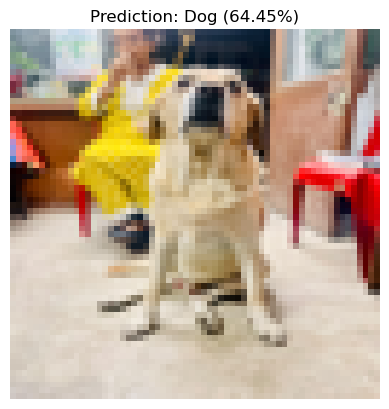

Result: Dog (Probability of being a dog: 0.6445)


In [45]:
# Replace with the path to your image
my_image_path = "/Users/rayquaza/Desktop/Resources/Deep Learning/Neural Network and Deep Learning/Deep Neural Networks/W4A1/dog_classifier/3.jpeg"

label, prob = predict_single_image(my_image_path, parameters)
print(f"Result: {label} (Probability of being a dog: {prob:.4f})")